In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [5]:
df = pd.read_csv("/content/Dataset-selected-columns.csv")

In [6]:
df.head()

,Unnamed: 0,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
0,0,0,2016,Honda,Honda Brio S MT,Brio,425000.0,9680.0,Petrol,Mumbai
1,1,1,2012,Nissan,Nissan Sunny XV Diesel,Sunny,325000.0,119120.0,Diesel,Mumbai
2,2,2,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2650000.0,64593.0,Diesel,Thane
3,3,3,2017,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,4195000.0,25000.0,Diesel,Mumbai
4,4,4,2012,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,475000.0,23800.0,Diesel,Mumbai


In [7]:
df.tail()

,Unnamed: 0,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
1720,1720,1720,2015,Hyundai,Hyundai Eon Era +,Eon,290000.0,38000.0,Petrol,Pune
1721,1721,1721,2011,Bentley,Bentley Continental Flying Spur W12,Continental,7500000.0,36000.0,Petrol,Pune
1722,1722,1722,2008,Mahindra-Renault,Mahindra-Renault Logan DLE 1.5 dci,Logan,185000.0,142522.0,Diesel,Pune
1723,1723,1723,1990,Mahindra,Mahindra Jeep CJ 500 D,Jeep,325000.0,18581.0,Diesel,Pune
1724,1724,1724,2017,Hyundai,Hyundai Creta SX Plus 1.6 AT CRDI,Creta,1395000.0,31028.0,Diesel,Pune


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1725 entries, 0 to 1724
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               1725 non-null   int64  
 1   Id                       1725 non-null   int64  
 2   year                     1725 non-null   int64  
 3   brand                    1725 non-null   object 
 4   full_model_name          1725 non-null   object 
 5   model_name               1725 non-null   object 
 6   price                    1725 non-null   float64
 7   distance_travelled(kms)  1725 non-null   float64
 8   fuel_type                1725 non-null   object 
 9   city                     1725 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 134.9+ KB


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
Unnamed: 0,0
Id,0
year,0
brand,0
full_model_name,0
model_name,0
price,0
distance_travelled(kms),0
fuel_type,0
city,0


In [12]:
#seperate the numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Unnamed: 0', 'Id', 'year', 'price', 'distance_travelled(kms)']

Categorical columns:
['brand', 'full_model_name', 'model_name', 'fuel_type', 'city']


In [13]:
#checking the missing values,duplicates and categories
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

for col in categorical_columns:
    print(f"\nCategories in {col}:")
    print(df[col].value_counts(dropna=False).head(20))

Missing values in each column:


,Missing Values
Unnamed: 0,0
Id,0
year,0
brand,0
full_model_name,0
model_name,0
price,0
distance_travelled(kms),0
fuel_type,0
city,0



Total missing values: 0

Duplicate rows: 0

Categories in brand:
brand
Hyundai          297
Maruti Suzuki    275
Honda            153
Mercedes-Benz    131
Toyota           117
BMW              111
Audi              98
Mahindra          93
Ford              78
Volkswagen        70
Renault           51
Skoda             45
Tata              44
Jaguar            30
Land Rover        28
Volvo             17
Nissan            13
Kia               12
MINI              10
Jeep              10
Name: count, dtype: int64

Categories in full_model_name:
full_model_name
Ford EcoSport Titanium 1.5L TDCi                 12
Toyota Innova Crysta 2.4 VX 8 STR [2016-2020]    11
Honda City 1.5 S MT                              11
Audi Q7 3.0 TDI quattro Premium Plus             11
Volkswagen Polo GT TSI                           11
Toyota Innova Crysta 2.4 VX 7 STR [2016-2020]     9
Renault Kwid 1.0 RXT AMT Opt [2016-2019]          9
Honda WR-V VX MT Diesel                           9
Mercedes-Benz C-Cl

In [14]:
# Preserve the original dataset for comparison
original_df = df.copy()
df = df.copy()

# Standardize column names
def clean_column_name(col):
    col = str(col).strip().lower()
    col = re.sub(r"[^a-z0-9]+", "_", col)
    return col.strip("_")

df.columns = [clean_column_name(c) for c in df.columns]

print("Standardized columns:")
print(df.columns.tolist())

# Remove exact duplicate rows
duplicates_removed = df.duplicated().sum()
df = df.drop_duplicates().copy()

# Normalize text categories
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Identify common car-data column names
def find_column(possible_names):
    for name in possible_names:
        if name in df.columns:
            return name
    return None

year_col = find_column(["year", "manufacturing_year", "model_year"])
price_col = find_column(["price", "selling_price", "sellingprice"])
distance_col = find_column([
    "distance_travelled_kms", "km_driven", "kms_driven",
    "kilometers_driven", "distance_travelled"
])
brand_col = find_column(["brand", "company", "manufacturer"])
fuel_col = find_column(["fuel_type", "fuel"])
city_col = find_column(["city", "location"])

# Convert important numerical columns
for col in [year_col, price_col, distance_col]:
    if col:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Mark clearly invalid values as missing
if price_col:
    df.loc[df[price_col] <= 0, price_col] = np.nan

if distance_col:
    df.loc[df[distance_col] < 0, distance_col] = np.nan

if year_col:
    df.loc[
        (df[year_col] < 1900) | (df[year_col] > 2026),
        year_col
    ] = np.nan

# Standardize common categorical labels
for col in [brand_col, fuel_col, city_col]:
    if col:
        df[col] = df[col].map(
            lambda x: x.title() if isinstance(x, str) else x
        )

# Remove rows missing the key fields needed for core analysis.
# Other missing values are retained.
key_columns = [
    c for c in [year_col, price_col, distance_col] if c
]

if key_columns:
    df = df.dropna(subset=key_columns).copy()

print("Duplicates removed:", duplicates_removed)
print("Rows before cleaning:", len(original_df))
print("Rows after cleaning:", len(df))
print("Columns after cleaning:", df.shape[1])

print("\nRemaining missing values:")
display(df.isnull().sum().to_frame("Missing Values"))

display(df.head())

Standardized columns:
['unnamed_0', 'id', 'year', 'brand', 'full_model_name', 'model_name', 'price', 'distance_travelled_kms', 'fuel_type', 'city']
Duplicates removed: 0
Rows before cleaning: 1725
Rows after cleaning: 1725
Columns after cleaning: 10

Remaining missing values:


,Missing Values
unnamed_0,0
id,0
year,0
brand,0
full_model_name,0
model_name,0
price,0
distance_travelled_kms,0
fuel_type,0
city,0


,unnamed_0,id,year,brand,full_model_name,model_name,price,distance_travelled_kms,fuel_type,city
0,0,0,2016.0,Honda,Honda Brio S MT,Brio,425000.0,9680.0,Petrol,Mumbai
1,1,1,2012.0,Nissan,Nissan Sunny XV Diesel,Sunny,325000.0,119120.0,Diesel,Mumbai
2,2,2,2017.0,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2650000.0,64593.0,Diesel,Thane
3,3,3,2017.0,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,4195000.0,25000.0,Diesel,Mumbai
4,4,4,2012.0,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,475000.0,23800.0,Diesel,Mumbai


In [15]:
#discriptive statictics
print("Numerical descriptive statistics:")
display(df.describe().T)

print("\nCategorical descriptive statistics:")
display(df.describe(include=["object"]).T)

if brand_col:
    print("\nMost common car brands:")
    display(df[brand_col].value_counts().head(10))

if fuel_col:
    print("\nFuel type distribution:")
    display(df[fuel_col].value_counts())

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
unnamed_0,1725.0,8.620000e+02,4.981089e+02,0.0,431.0,862.0,1293.0,1724.0
id,1725.0,8.620000e+02,4.981089e+02,0.0,431.0,862.0,1293.0,1724.0
year,1725.0,2.015391e+03,3.207504e+00,1990.0,2013.0,2016.0,2018.0,2021.0
price,1725.0,1.494837e+06,1.671658e+06,62500.0,545000.0,875000.0,1825000.0,14700000.0
distance_travelled_kms,1725.0,5.384826e+04,4.472554e+04,350.0,29000.0,49000.0,70500.0,790000.0



Categorical descriptive statistics:


,count,unique,top,freq
brand,1725,31,Hyundai,297
full_model_name,1725,750,Ford EcoSport Titanium 1.5L TDCi,12
model_name,1725,169,Creta,71
fuel_type,1725,5,Diesel,922
city,1725,15,Chennai,493



Most common car brands:


,count
brand,
Hyundai,297
Maruti Suzuki,275
Honda,153
Mercedes-Benz,131
Toyota,117
Bmw,111
Audi,98
Mahindra,93
Ford,78



Fuel type distribution:


,count
fuel_type,
Diesel,922
Petrol,788
Cng + 1,8
Petrol + 1,6
Hybrid,1


In [16]:
#vehical-age column
if year_col:
    analysis_year = 2026
    df["vehicle_age"] = analysis_year - df[year_col]
    print("Vehicle age calculated using reference year:", analysis_year)
    display(df[["vehicle_age"]].describe())
else:
    print("Year column not found; vehicle age cannot be calculated.")

Vehicle age calculated using reference year: 2026


,vehicle_age
count,1725.000000
mean,10.609275
std,3.207504
min,5.000000
25%,8.000000
50%,10.000000
75%,13.000000
max,36.000000


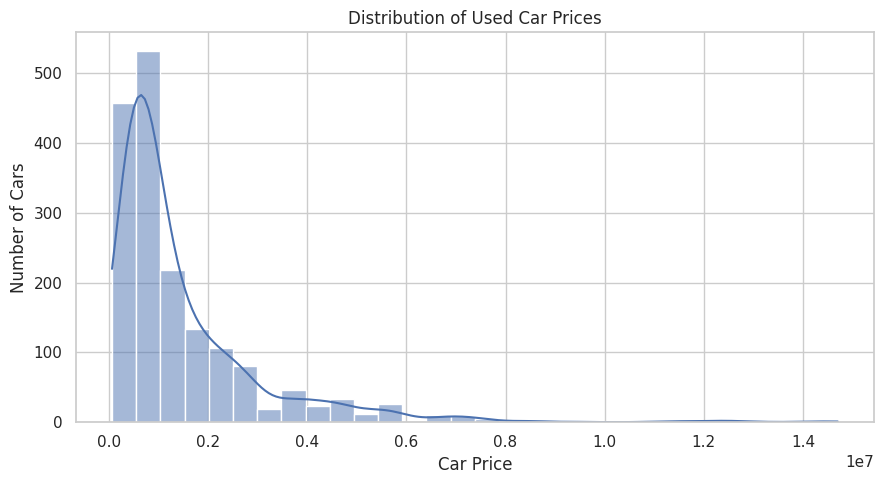

Observation: Use the histogram to determine whether prices are concentrated in a particular range or skewed by expensive cars.


In [17]:
#Chart 1:car price distribution
if price_col:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[price_col], bins=30, kde=True)
    plt.title("Distribution of Used Car Prices")
    plt.xlabel("Car Price")
    plt.ylabel("Number of Cars")
    plt.tight_layout()
    plt.show()

    print("Observation: Use the histogram to determine whether prices "
          "are concentrated in a particular range or skewed by expensive cars.")

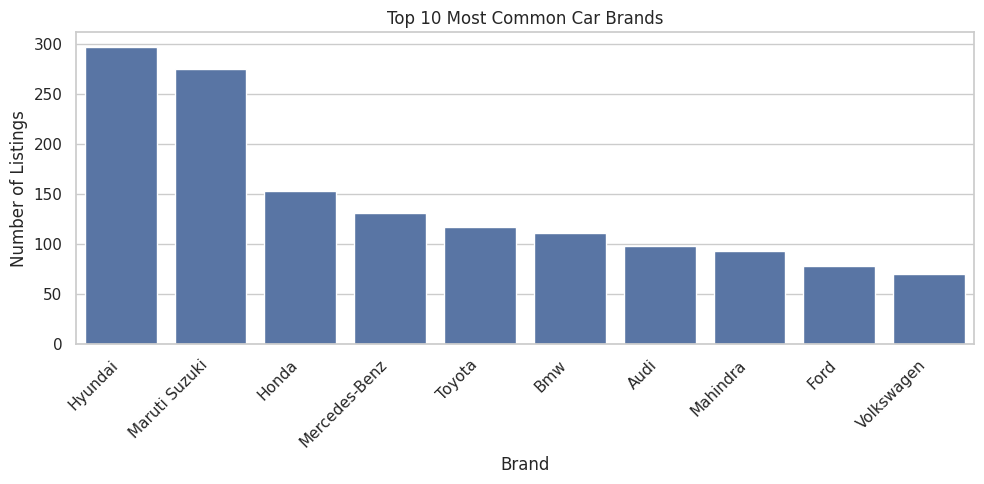

Observation: The bars identify which brands appear most frequently in the selected dataset.


In [18]:
#Chart2 : most common car brands
if brand_col:
    brand_counts = df[brand_col].value_counts().head(10)

    plt.figure(figsize=(10, 5))
    sns.barplot(x=brand_counts.index, y=brand_counts.values)
    plt.title("Top 10 Most Common Car Brands")
    plt.xlabel("Brand")
    plt.ylabel("Number of Listings")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print("Observation: The bars identify which brands appear most "
          "frequently in the selected dataset.")

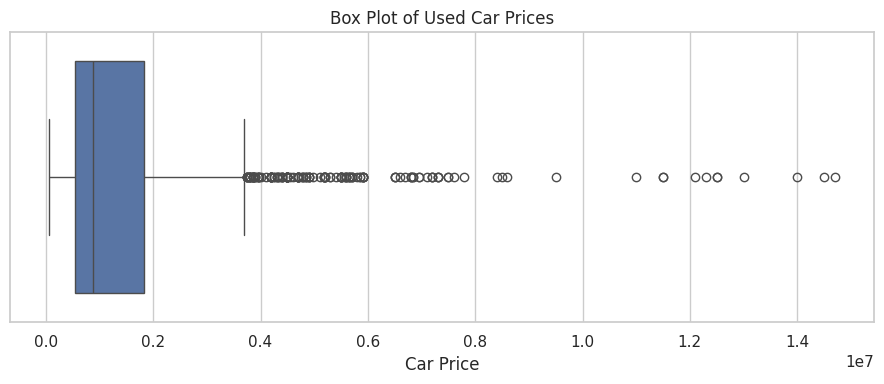

Potential price outliers: 158
Observation: Points beyond the whiskers are potential outliers and should be investigated, not automatically deleted.


In [19]:
#Chart3 : price outliers
if price_col:
    plt.figure(figsize=(9, 4))
    sns.boxplot(x=df[price_col])
    plt.title("Box Plot of Used Car Prices")
    plt.xlabel("Car Price")
    plt.tight_layout()
    plt.show()

    q1 = df[price_col].quantile(0.25)
    q3 = df[price_col].quantile(0.75)
    iqr = q3 - q1

    outlier_mask = (
        (df[price_col] < q1 - 1.5 * iqr) |
        (df[price_col] > q3 + 1.5 * iqr)
    )

    print("Potential price outliers:", int(outlier_mask.sum()))
    print("Observation: Points beyond the whiskers are potential "
          "outliers and should be investigated, not automatically deleted.")

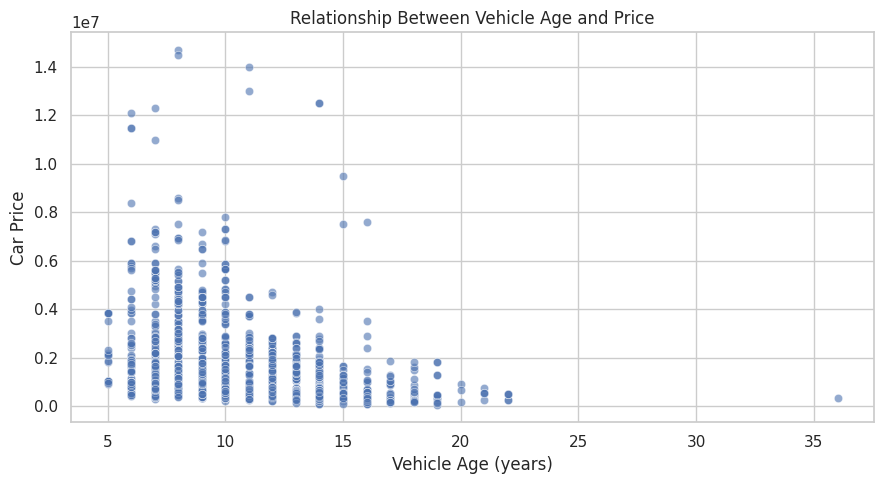

Pearson correlation: -0.288
Observation: A negative correlation would indicate that older cars tend to have lower prices in this dataset.


In [20]:
#Chart4 : vehical_ages versus price
if price_col and "vehicle_age" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df, x="vehicle_age", y=price_col, alpha=0.6
    )
    plt.title("Relationship Between Vehicle Age and Price")
    plt.xlabel("Vehicle Age (years)")
    plt.ylabel("Car Price")
    plt.tight_layout()
    plt.show()

    corr = df["vehicle_age"].corr(df[price_col])
    print(f"Pearson correlation: {corr:.3f}")
    print("Observation: A negative correlation would indicate that "
          "older cars tend to have lower prices in this dataset.")

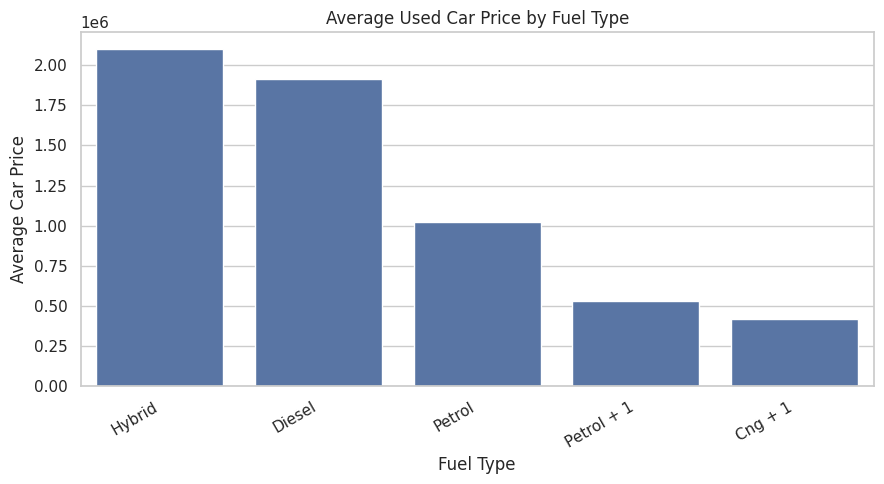

Observation: Compare average prices between fuel categories. Differences may also reflect brand, age, or vehicle type.


In [21]:
#Chart5 : average price of the fule types
if price_col and fuel_col:
    fuel_prices = (
        df.groupby(fuel_col)[price_col]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))
    sns.barplot(x=fuel_prices.index, y=fuel_prices.values)
    plt.title("Average Used Car Price by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Average Car Price")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    print("Observation: Compare average prices between fuel categories. "
          "Differences may also reflect brand, age, or vehicle type.")

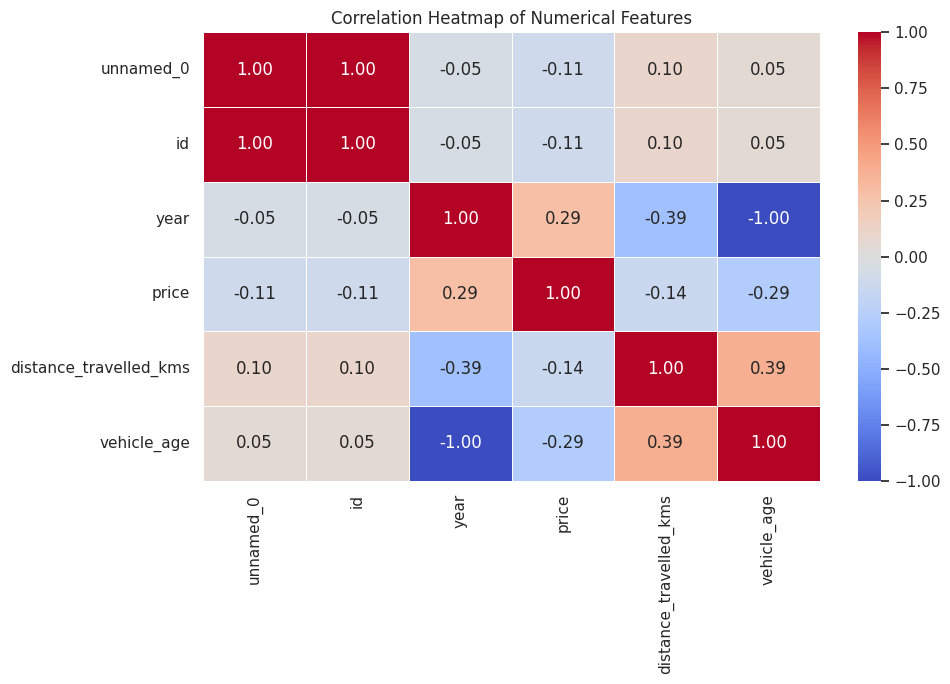

Observation: Values near +1 indicate a strong positive linear relationship, while values near -1 indicate a strong negative linear relationship.


In [22]:
#Chart6 : correlation heatmap
numeric_df = df.select_dtypes(include=["number"])

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    correlation = numeric_df.corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()

    print("Observation: Values near +1 indicate a strong positive "
          "linear relationship, while values near -1 indicate a strong "
          "negative linear relationship.")

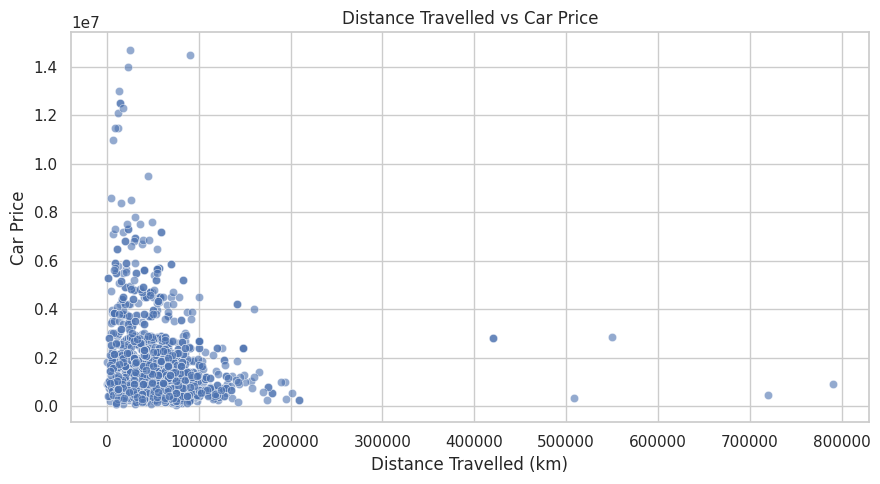

Correlation between distance and price: -0.137

Average price by brand (brands with at least 5 records):


,mean,count
brand,,
Porsche,5.080000e+06,5
Land Rover,4.371071e+06,28
Jaguar,3.804500e+06,30
Volvo,3.782353e+06,17
Mercedes-Benz,3.281939e+06,131
Mini,3.244500e+06,10
Bmw,3.242009e+06,111
Audi,2.247031e+06,98
Jeep,1.923000e+06,10


In [23]:
#Bivarient analysis
if price_col and distance_col:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df, x=distance_col, y=price_col, alpha=0.6
    )
    plt.title("Distance Travelled vs Car Price")
    plt.xlabel("Distance Travelled (km)")
    plt.ylabel("Car Price")
    plt.tight_layout()
    plt.show()

    print(
        "Correlation between distance and price:",
        round(df[distance_col].corr(df[price_col]), 3)
    )

if brand_col and price_col:
    print("\nAverage price by brand (brands with at least 5 records):")

    brand_summary = df.groupby(brand_col)[price_col].agg(
        ["mean", "count"]
    )

    brand_summary = (
        brand_summary[brand_summary["count"] >= 5]
        .sort_values("mean", ascending=False)
    )

    display(brand_summary.head(10))

Median car price by age group and fuel type:


fuel_type,Cng + 1,Diesel,Hybrid,Petrol,Petrol + 1
age_group,,,,,
4-7 years,465000.0,2325000.0,2100000.0,1050000.0,950000.0
8-12 years,445000.0,1395000.0,NaN,625000.0,NaN
Over 12 years,320000.0,925000.0,NaN,355000.0,260000.0


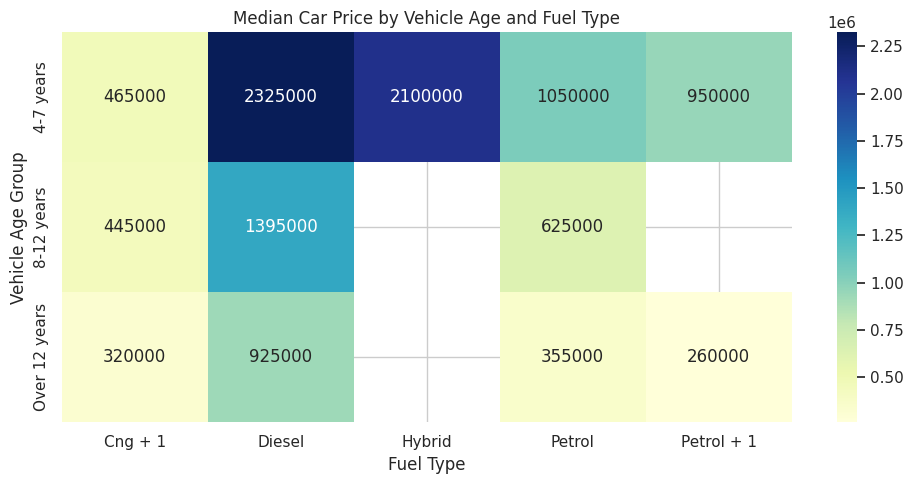

In [24]:
#Multivarient analysis
if fuel_col and price_col and "vehicle_age" in df.columns:
    df["age_group"] = pd.cut(
        df["vehicle_age"],
        bins=[-1, 3, 7, 12, 100],
        labels=["0-3 years", "4-7 years",
                "8-12 years", "Over 12 years"]
    )

    grouped = df.pivot_table(
        index="age_group",
        columns=fuel_col,
        values=price_col,
        aggfunc="median",
        observed=False
    )

    print("Median car price by age group and fuel type:")
    display(grouped)

    plt.figure(figsize=(10, 5))
    sns.heatmap(grouped, annot=True, fmt=".0f", cmap="YlGnBu")
    plt.title("Median Car Price by Vehicle Age and Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Vehicle Age Group")
    plt.tight_layout()
    plt.show()
else:
    print("Multivariate age and fuel comparison is unavailable "
          "because one or more required columns are missing.")

In [25]:
print("FINAL DATA-BASED FINDINGS\n")

print(f"1. The cleaned dataset contains {len(df)} car records "
      f"and {df.shape[1]} columns.")

if brand_col:
    common_brand = df[brand_col].mode().iloc[0]
    common_count = int((df[brand_col] == common_brand).sum())
    print(f"2. The most common brand is {common_brand}, "
          f"with {common_count} records.")

if price_col:
    print(f"3. The median car price is "
          f"{df[price_col].median():,.2f}.")

if price_col and year_col:
    price_age_corr = df["vehicle_age"].corr(df[price_col])
    print(f"4. The correlation between vehicle age and price is "
          f"{price_age_corr:.3f}.")

if price_col and distance_col:
    distance_corr = df[distance_col].corr(df[price_col])
    print(f"5. The correlation between distance travelled and price is "
          f"{distance_corr:.3f}.")

if fuel_col:
    print("6. Fuel type counts:")
    print(df[fuel_col].value_counts().to_string())

if price_col:
    print(f"7. The price range is "
          f"{df[price_col].min():,.2f} to "
          f"{df[price_col].max():,.2f}.")

FINAL DATA-BASED FINDINGS

1. The cleaned dataset contains 1725 car records and 12 columns.
2. The most common brand is Hyundai, with 297 records.
3. The median car price is 875,000.00.
4. The correlation between vehicle age and price is -0.288.
5. The correlation between distance travelled and price is -0.137.
6. Fuel type counts:
fuel_type
Diesel        922
Petrol        788
Cng + 1         8
Petrol + 1      6
Hybrid          1
7. The price range is 62,500.00 to 14,700,000.00.


In [26]:
output_file = "cleaned_used_car_dataset.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")

from google.colab import files
files.download(output_file)

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>